In [2]:
import sys
import osmnx as ox
import networkx as nx


print("Python:", sys.version.split()[0])
print("Interpretador:", sys.executable)
print("OSMnx:", ox.__version__)
print("NetworkX:", nx.__version__)

Python: 3.12.13
Interpretador: /home/emanu/projetos/ftl-projeto-final/.venv/bin/python
OSMnx: 2.1.1
NetworkX: 3.7


In [3]:
from pathlib  import Path
import geopandas as gpd
import matplotlib.pyplot as plt

caminho = Path("../dados/brutos/bairros/prefeitura_bairro.gpkg")
#print(Path.exists(caminho))
pref_bairro = gpd.read_file(caminho)
pref_bairro.head()

/home/emanu/projetos/ftl-projeto-final/.venv/lib/python3.12/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'prefeitura_bairro.gpkg': 'prefeituras_bairro_a' (default), 'layer_styles'. Specify layer parameter to avoid this warning.
  result = read_func(


,PREF_BAIRR,COD_PBR,ID,QTD_BAIRRO,area,geometry
0,Prefeitura-bairro IV - Itapuã / Ipitanga,IV,4,17,94380440.97,"MULTIPOLYGON (((563183.372 8565464.348, 563137..."
1,Prefeitura-bairro X - Valéria,X,10,4,25325166.31,"MULTIPOLYGON (((560318.999 8574966.432, 560166..."
2,Prefeitura-bairro V - Cidade Baixa,V,5,14,8132459.00,"MULTIPOLYGON (((553769.31 8569249.552, 553767...."
3,Prefeitura-bairro III - Cajazeiras,III,3,17,22160586.15,"MULTIPOLYGON (((566822.94 8573201.26, 566811.8..."
4,Prefeitura-bairro IX - Pau da Lima,IX,9,13,19905726.69,"MULTIPOLYGON (((563789.494 8569538.91, 563559...."


In [4]:
piloto = pref_bairro.loc[
    pref_bairro["COD_PBR"] == "I"
].copy()
piloto = piloto.to_crs(epsg=31984)

#Margem inical de 2km
margem_m = 2000

area_busca = piloto.copy()
area_busca["geometry"] =  piloto.geometry.buffer(margem_m)

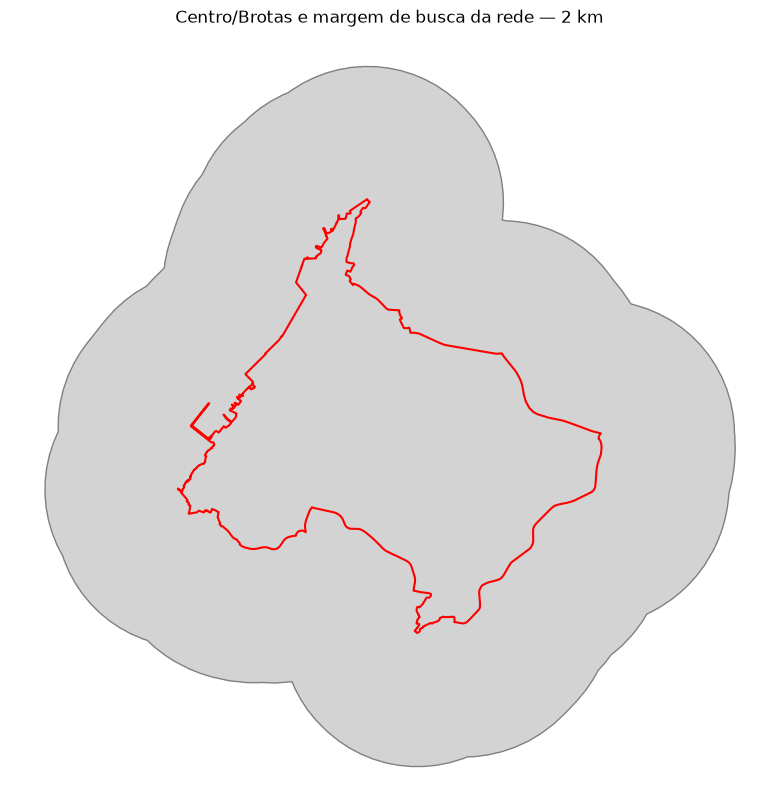

In [5]:
fig, ax = plt.subplots(figsize=(10, 10))

area_busca.plot(ax=ax, facecolor="lightgray", edgecolor="gray")
piloto.boundary.plot(ax=ax, color="red", linewidth=1.5)

ax.set_title("Centro/Brotas e margem de busca da rede — 2 km")
ax.set_axis_off()

plt.show()

In [6]:
area_busca_wgs84 = area_busca.to_crs(epsg=4326)
poligono_busca = area_busca_wgs84.geometry.iloc[0]

#consulta o OpenStreetMap
ox.settings.use_cache = True
ox.settings.log_console = True

rede = ox.graph_from_polygon(
    poligono_busca,
    network_type="walk",
    simplify=True,
    retain_all=True,
    truncate_by_edge=True
)

In [7]:
print("Tipo:", type(rede).__name__)
print("Nós:", rede.number_of_nodes())
print("Arestas:", rede.number_of_edges())
print("CRS:", rede.graph["crs"])

Tipo: MultiDiGraph
Nós: 16231
Arestas: 44112
CRS: epsg:4326


In [8]:
componentes = sorted(
    nx.weakly_connected_components(rede),
    key=len,
    reverse=True
)

print("Componentes:", len(componentes))
print("Nós nos 5 maiores:", [len(c) for c in componentes[:5]])

print(
    "Percentual de nós no maior componente:",
    f"{100 * len(componentes[0]) / rede.number_of_nodes():.2f}%"
)

Componentes: 65
Nós nos 5 maiores: [16043, 16, 14, 10, 6]
Percentual de nós no maior componente: 98.84%


In [9]:
rede_utm = ox.project_graph(rede, to_crs="EPSG:31984")

nos, arestas = ox.graph_to_gdfs(rede_utm)

nos["componente_principal"] = nos.index.isin(componentes[0])

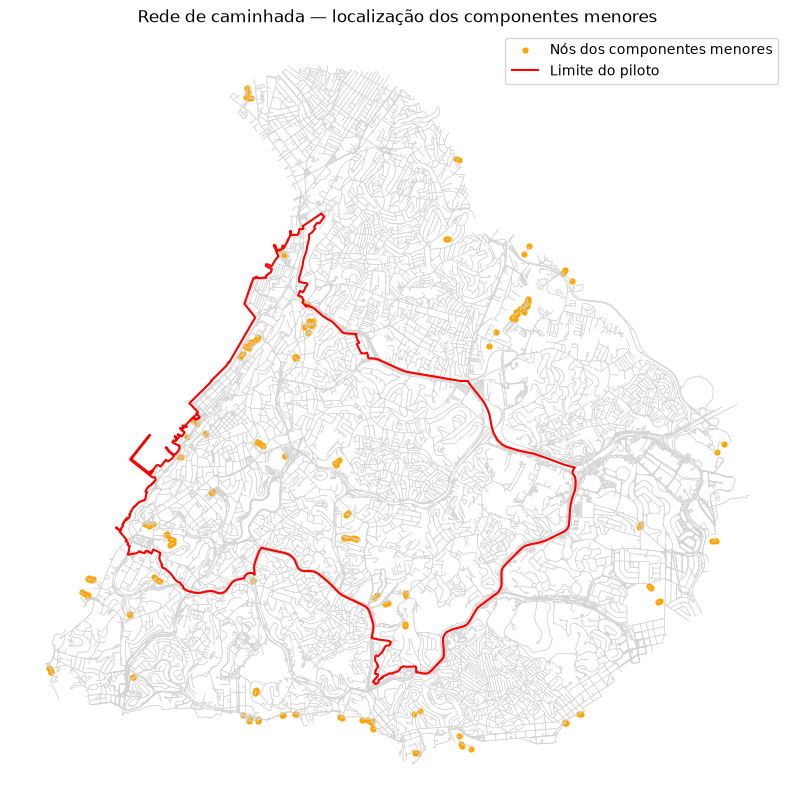

In [10]:
fig, ax = plt.subplots(figsize=(10, 10))

arestas.plot(ax=ax, color="lightgray", linewidth=0.4)

nos.loc[~nos["componente_principal"]].plot(
    ax=ax,
    color="orange",
    markersize=12,
    label="Nós dos componentes menores"
)

piloto.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5,
    label="Limite do piloto"
)

ax.set_title("Rede de caminhada — localização dos componentes menores")
ax.set_axis_off()
ax.legend()

plt.show()

In [11]:
nos_menores = nos.loc[
    ~nos["componente_principal"]
].copy()

nos_menores_no_piloto = nos_menores.loc[
    nos_menores.geometry.intersects(
        piloto.geometry.iloc[0]
    )
]

print("Nós dos componentes menores:", len(nos_menores))
print("Desses, dentro do piloto:", len(nos_menores_no_piloto))

Nós dos componentes menores: 188
Desses, dentro do piloto: 83


In [12]:
grade = gpd.read_file(
    Path("../dados/processados/centro_brotas_h3_res10_populacao.gpkg"),
    layer="populacao_estimada"
)

unidades = gpd.read_file(
    Path("../dados/processados/ubs_usf_salvador.gpkg"),
    layer="ubs_usf"
)

pontos_grade = grade.copy()
pontos_grade["geometry"] = grade.geometry.representative_point()


unidades_busca = unidades.loc[
    unidades.geometry.intersects(area_busca.geometry.iloc[0])
].copy()

In [13]:
pontos_grade["no_rede"], pontos_grade["dist_no_m"] = (
    ox.distance.nearest_nodes(
        rede_utm,
        X=pontos_grade.geometry.x,
        Y=pontos_grade.geometry.y,
        return_dist=True
    )
)

unidades_busca["no_rede"], unidades_busca["dist_no_m"] = (
    ox.distance.nearest_nodes(
        rede_utm,
        X=unidades_busca.geometry.x,
        Y=unidades_busca.geometry.y,
        return_dist=True
    )
)

In [14]:
print("Unidades na área de busca:", len(unidades_busca))

print(
    "Células associadas a componentes menores:",
    (~pontos_grade["no_rede"].isin(componentes[0])).sum()
)

print(
    "Unidades associadas a componentes menores:",
    (~unidades_busca["no_rede"].isin(componentes[0])).sum()
)

print("Distâncias das células aos nós:")
print(pontos_grade["dist_no_m"].describe())

print("Distâncias das unidades aos nós:")
print(unidades_busca["dist_no_m"].describe())

Unidades na área de busca: 34
Células associadas a componentes menores: 16
Unidades associadas a componentes menores: 0
Distâncias das células aos nós:
count    1145.000000
mean       38.788531
std        34.527686
min         1.013018
25%        19.664567
50%        31.753905
75%        49.247219
max       416.136406
Name: dist_no_m, dtype: float64
Distâncias das unidades aos nós:
count    34.000000
mean     26.680876
std      13.807581
min       7.373917
25%      19.635063
50%      24.361836
75%      30.198581
max      69.804621
Name: dist_no_m, dtype: float64


In [15]:
celulas_isoladas = pontos_grade.loc[
    ~pontos_grade["no_rede"].isin(componentes[0])
].copy()

print("Células:", len(celulas_isoladas))
print(
    "População estimada:",
    f"{celulas_isoladas['pop_estimada'].sum():.2f}"
)

print(
    celulas_isoladas[
        ["h3_id", "pop_estimada", "no_rede", "dist_no_m"]
    ]
    .sort_values("dist_no_m", ascending=False)
    .to_string(index=False)
)

Células: 16
População estimada: 2871.79
          h3_id  pop_estimada     no_rede  dist_no_m
8a8116b1db37fff    230.973428 13321011316  75.414672
8a8116b1d867fff     39.669156  7272596454  67.432637
8a8116a24827fff      4.991655 12247230656  55.019729
8a8116b08577fff    118.087972 12289354228  54.240674
8a8116b1da57fff    601.707001  8147485395  46.917205
8a8116b1da47fff    666.789337  8147485346  42.141795
8a8116b0a52ffff     41.827725  7267103686  38.643717
8a8116a24d57fff    223.428363 12840809677  31.753905
8a8116b0ad87fff    193.265181 11670720304  27.188317
8a8116a2490ffff      4.991616 12247230677  27.084792
8a8116b08097fff     95.662037 13013000919  25.548739
8a8116b0e49ffff    215.302428 13320996709  25.217584
8a8116b0aa67fff    155.966322 13208640787  20.733922
8a8116a24d47fff    100.573951 12840809666  19.131614
8a8116b1d857fff     45.051669  9010178599  14.623809
8a8116b08557fff    133.499033 12289354260  14.285999


In [16]:
print(
    pontos_grade.nlargest(5, "dist_no_m")[
        ["h3_id", "pop_estimada", "no_rede", "dist_no_m"]
    ].to_string(index=False)
)

          h3_id  pop_estimada    no_rede  dist_no_m
8a8116b0bd2ffff           0.0 1141620900 416.136406
8a8116b086dffff           0.0 1141620900 409.826660
8a8116b086d7fff           0.0 1141620900 398.189357
8a8116b086c7fff           0.0 5140499715 363.966880
8a8116b086e7fff           0.0 5140499715 337.478637


In [17]:
celulas_isoladas = pontos_grade.loc[
    ~pontos_grade["no_rede"].isin(componentes[0])
].copy()

print("Células em componentes menores:", len(celulas_isoladas))
print(
    "População estimada nessas células:",
    f"{celulas_isoladas['pop_estimada'].sum():.2f}"
)

print(
    celulas_isoladas[
        ["h3_id", "pop_estimada", "dist_no_m"]
    ].to_string(index=False)
)

Células em componentes menores: 16
População estimada nessas células: 2871.79
          h3_id  pop_estimada  dist_no_m
8a8116a24827fff      4.991655  55.019729
8a8116a2490ffff      4.991616  27.084792
8a8116a24d47fff    100.573951  19.131614
8a8116a24d57fff    223.428363  31.753905
8a8116b08097fff     95.662037  25.548739
8a8116b08557fff    133.499033  14.285999
8a8116b08577fff    118.087972  54.240674
8a8116b0a52ffff     41.827725  38.643717
8a8116b0aa67fff    155.966322  20.733922
8a8116b0ad87fff    193.265181  27.188317
8a8116b0e49ffff    215.302428  25.217584
8a8116b1d857fff     45.051669  14.623809
8a8116b1d867fff     39.669156  67.432637
8a8116b1da47fff    666.789337  42.141795
8a8116b1da57fff    601.707001  46.917205
8a8116b1db37fff    230.973428  75.414672


In [18]:
id_caso = "8a8116b1da47fff"

caso = pontos_grade.loc[
    pontos_grade["h3_id"] == id_caso
]

no_caso = caso["no_rede"].iloc[0]

componente_caso = next(
    componente
    for componente in componentes
    if no_caso in componente
)

print("Nós no componente do caso:", len(componente_caso))

Nós no componente do caso: 6


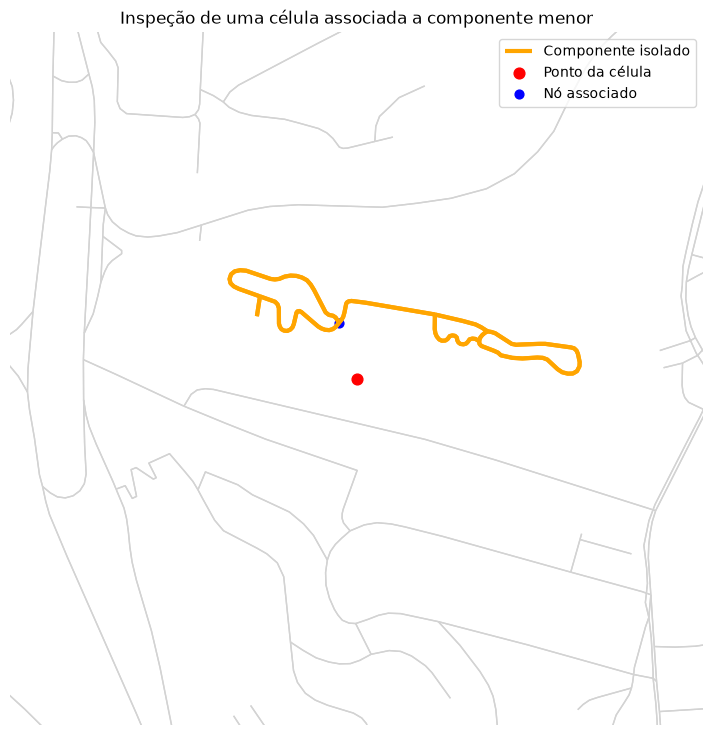

In [19]:
arestas_caso = arestas.loc[
    arestas.index.get_level_values("u").isin(componente_caso)
    & arestas.index.get_level_values("v").isin(componente_caso)
]

fig, ax = plt.subplots(figsize=(9, 9))

arestas.plot(ax=ax, color="lightgray", linewidth=1)

arestas_caso.plot(
    ax=ax,
    color="orange",
    linewidth=3,
    label="Componente isolado"
)

caso.plot(
    ax=ax,
    color="red",
    markersize=60,
    label="Ponto da célula"
)

nos.loc[[no_caso]].plot(
    ax=ax,
    color="blue",
    markersize=40,
    label="Nó associado"
)

x = caso.geometry.x.iloc[0]
y = caso.geometry.y.iloc[0]

ax.set_xlim(x - 250, x + 250)
ax.set_ylim(y - 250, y + 250)

ax.set_title("Inspeção de uma célula associada a componente menor")
ax.set_axis_off()
ax.legend()

plt.show()

In [20]:
colunas = [
    coluna
    for coluna in [
        "osmid", "name", "highway", "access",
        "foot", "service", "length"
    ]
    if coluna in arestas_caso.columns
]

print(arestas_caso[colunas].to_string())

                                            osmid name  highway access service      length
u          v          key                                                                 
8147485324 8147485325 0                 875318080  NaN  footway    NaN     NaN   14.552527
8147485325 8147485324 0                 875318080  NaN  footway    NaN     NaN   14.552527
           8147485346 0                 875318082  NaN  footway    NaN     NaN   90.914429
                      1                 875318082  NaN  footway    NaN     NaN  127.833378
8147485346 8147485325 0                 875318082  NaN  footway    NaN     NaN  127.833378
                      1                 875318082  NaN  footway    NaN     NaN   90.914429
           8147485399 0                 875318082  NaN  footway    NaN     NaN   80.536783
8147485399 8147485365 0                 875318081  NaN  footway    NaN     NaN   55.090532
           8147485395 0                 875318082  NaN  footway    NaN     NaN   40.138941

In [21]:
ponto_caso = caso.geometry.iloc[0]

aresta_proxima, distancia_aresta = ox.distance.nearest_edges(
    rede_utm,
    X=ponto_caso.x,
    Y=ponto_caso.y,
    return_dist=True
)

u, v, chave = aresta_proxima

print(f"Distância ao nó escolhido: {caso['dist_no_m'].iloc[0]:.2f} m")
print(f"Distância à aresta mais próxima: {distancia_aresta:.2f} m")
print("Aresta:", aresta_proxima)
print("Pertence ao componente principal:", u in componentes[0])

print(arestas.loc[aresta_proxima, colunas].to_string())

Distância ao nó escolhido: 42.14 m
Distância à aresta mais próxima: 31.38 m
Aresta: (1588444140, 13321319363, 0)
Pertence ao componente principal: True
osmid                            49242054
name       Rua Nossa Senhora de Guadalupe
highway                       residential
access                                NaN
service                               NaN
length                         356.121847


In [22]:
diagnostico_arestas = celulas_isoladas.copy()

arestas_proximas, distancias = ox.distance.nearest_edges(
    rede_utm,
    X=diagnostico_arestas.geometry.x,
    Y=diagnostico_arestas.geometry.y,
    return_dist=True
)

diagnostico_arestas["dist_aresta_m"] = distancias

diagnostico_arestas["aresta_no_principal"] = [
    u in componentes[0]
    for u, v, chave in arestas_proximas
]

In [23]:
print(
    diagnostico_arestas[
        [
            "h3_id",
            "pop_estimada",
            "dist_no_m",
            "dist_aresta_m",
            "aresta_no_principal"
        ]
    ].to_string(index=False)
)

          h3_id  pop_estimada  dist_no_m  dist_aresta_m  aresta_no_principal
8a8116a24827fff      4.991655  55.019729       1.976773                False
8a8116a2490ffff      4.991616  27.084792       5.986436                False
8a8116a24d47fff    100.573951  19.131614       5.431252                False
8a8116a24d57fff    223.428363  31.753905       3.988816                 True
8a8116b08097fff     95.662037  25.548739       3.053613                False
8a8116b08557fff    133.499033  14.285999      13.447095                False
8a8116b08577fff    118.087972  54.240674      54.240674                False
8a8116b0a52ffff     41.827725  38.643717      38.627627                False
8a8116b0aa67fff    155.966322  20.733922       1.076328                 True
8a8116b0ad87fff    193.265181  27.188317       7.492483                False
8a8116b0e49ffff    215.302428  25.217584       2.228029                False
8a8116b1d857fff     45.051669  14.623809      14.623809                False

Nós no componente do caso: 6


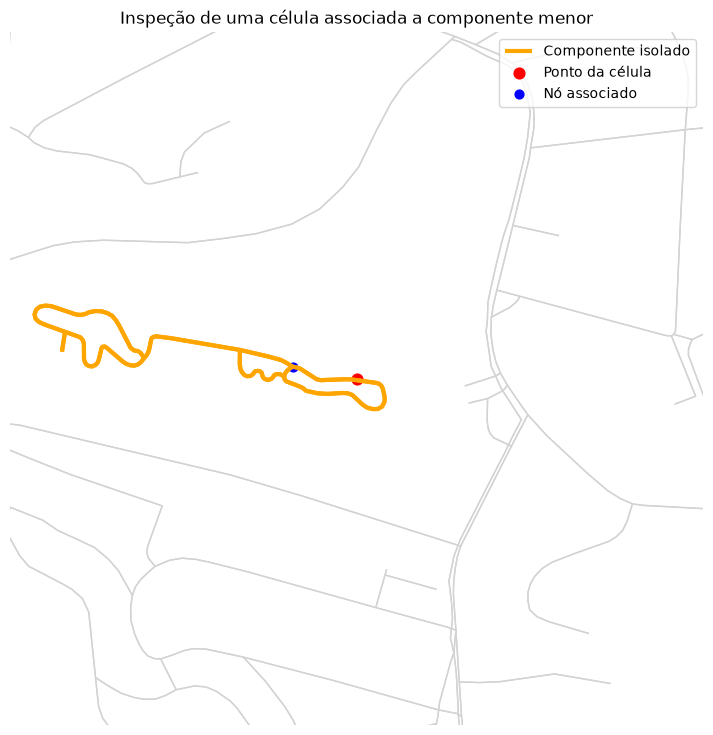

In [24]:
id_caso = "8a8116b1da57fff"

caso = pontos_grade.loc[
    pontos_grade["h3_id"] == id_caso
]

no_caso = caso["no_rede"].iloc[0]

componente_caso = next(
    componente
    for componente in componentes
    if no_caso in componente
)

print("Nós no componente do caso:", len(componente_caso))

arestas_caso = arestas.loc[
    arestas.index.get_level_values("u").isin(componente_caso)
    & arestas.index.get_level_values("v").isin(componente_caso)
]

fig, ax = plt.subplots(figsize=(9, 9))

arestas.plot(ax=ax, color="lightgray", linewidth=1)

arestas_caso.plot(
    ax=ax,
    color="orange",
    linewidth=3,
    label="Componente isolado"
)

caso.plot(
    ax=ax,
    color="red",
    markersize=60,
    label="Ponto da célula"
)

nos.loc[[no_caso]].plot(
    ax=ax,
    color="blue",
    markersize=40,
    label="Nó associado"
)

x = caso.geometry.x.iloc[0]
y = caso.geometry.y.iloc[0]

ax.set_xlim(x - 250, x + 250)
ax.set_ylim(y - 250, y + 250)

ax.set_title("Inspeção de uma célula associada a componente menor")
ax.set_axis_off()
ax.legend()

plt.show()

In [25]:
print("Nós do componente:", sorted(componente_caso))



Nós do componente: [8147485324, 8147485325, 8147485346, 8147485365, 8147485395, 8147485399]


In [26]:
ponto_wgs84 = caso.to_crs(epsg=4326).geometry.iloc[0]

print(
    "https://www.openstreetmap.org/"
    f"?mlat={ponto_wgs84.y}&mlon={ponto_wgs84.x}"
    f"#map=19/{ponto_wgs84.y}/{ponto_wgs84.x}"
)

https://www.openstreetmap.org/?mlat=-12.988845764017553&mlon=-38.49375009528074#map=19/-12.988845764017553/-38.49375009528074


In [27]:
celulas_arestas = pontos_grade.copy()
unidades_arestas = unidades_busca.copy()

for tabela in [celulas_arestas, unidades_arestas]:
    ids_arestas, distancias = ox.distance.nearest_edges(
        rede_utm,
        X=tabela.geometry.x,
        Y=tabela.geometry.y,
        return_dist=True
    )

    tabela["aresta_u"] = [u for u, v, chave in ids_arestas]
    tabela["aresta_v"] = [v for u, v, chave in ids_arestas]
    tabela["aresta_chave"] = [chave for u, v, chave in ids_arestas]
    tabela["dist_aresta_m"] = distancias

    tabela["aresta_no_principal"] = (
        tabela["aresta_u"].isin(componentes[0])
    )

In [28]:
for nome, tabela in [
    ("Células", celulas_arestas),
    ("Unidades", unidades_arestas)
]:
    print(nome)
    print("Total:", len(tabela))
    print(
        "Aresta mais próxima em componente menor:",
        (~tabela["aresta_no_principal"]).sum()
    )
    print(tabela["dist_aresta_m"].describe())
    print()

Células
Total: 1145
Aresta mais próxima em componente menor: 14
count    1145.000000
mean       20.080630
std        32.521633
min         0.000047
25%         5.508260
50%        12.647536
75%        24.224538
max       416.136406
Name: dist_aresta_m, dtype: float64

Unidades
Total: 34
Aresta mais próxima em componente menor: 0
count    34.000000
mean     13.457066
std       4.920011
min       5.545281
25%      10.052180
50%      13.320816
75%      15.737542
max      26.039109
Name: dist_aresta_m, dtype: float64



In [29]:
celulas_arestas["no_no_principal"] = (
    celulas_arestas["no_rede"].isin(componentes[0])
)

mudancas = celulas_arestas.loc[
    celulas_arestas["no_no_principal"]
    != celulas_arestas["aresta_no_principal"]
].copy()

print(
    mudancas[
        [
            "h3_id",
            "pop_estimada",
            "no_no_principal",
            "aresta_no_principal",
            "dist_no_m",
            "dist_aresta_m"
        ]
    ].to_string(index=False)
)

print(
    "População estimada associada a componentes menores por arestas:",
    f"{celulas_arestas.loc[
        ~celulas_arestas['aresta_no_principal'],
        'pop_estimada'
    ].sum():.2f}"
)

          h3_id  pop_estimada  no_no_principal  aresta_no_principal  dist_no_m  dist_aresta_m
8a8116a24d57fff    223.428363            False                 True  31.753905       3.988816
8a8116b0aa67fff    155.966322            False                 True  20.733922       1.076328
8a8116b0bda7fff      3.515005             True                False 100.702286      92.749664
8a8116b1d867fff     39.669156            False                 True  67.432637      48.650227
8a8116b1da47fff    666.789337            False                 True  42.141795      31.378260
8a8116b1db17fff    237.551356             True                False  44.444891      11.965440
População estimada associada a componentes menores por arestas: 2027.00


In [30]:
id_teste = "8a8116b1da47fff"

registro = celulas_arestas.loc[
    celulas_arestas["h3_id"] == id_teste
].iloc[0]

id_aresta = (
    registro["aresta_u"],
    registro["aresta_v"],
    registro["aresta_chave"]
)

linha = arestas.loc[id_aresta, "geometry"]
ponto_origem = registro.geometry

posicao = linha.project(ponto_origem)
ponto_entrada = linha.interpolate(posicao)

print(f"Distância até a aresta: {ponto_origem.distance(ponto_entrada):.2f} m")
print(f"Comprimento geométrico da aresta: {linha.length:.2f} m")
print(f"Posição desde o início da linha: {posicao:.2f} m")

Distância até a aresta: 31.38 m
Comprimento geométrico da aresta: 356.24 m
Posição desde o início da linha: 125.85 m


In [31]:
from shapely.geometry import Point

u, v, chave = id_aresta

inicio = Point(linha.coords[0])
fim = Point(linha.coords[-1])

no_u = nos.loc[u, "geometry"]
no_v = nos.loc[v, "geometry"]

print(f"Início → u: {inicio.distance(no_u):.6f} m")
print(f"Início → v: {inicio.distance(no_v):.6f} m")
print(f"Fim → u: {fim.distance(no_u):.6f} m")
print(f"Fim → v: {fim.distance(no_v):.6f} m")

Início → u: 0.000000 m
Início → v: 346.608702 m
Fim → u: 346.608702 m
Fim → v: 0.000000 m


In [32]:
comprimento_rede = float(arestas.loc[id_aresta, "length"])

fracao = posicao / linha.length

dist_entrada_u = fracao * comprimento_rede
dist_entrada_v = (1 - fracao) * comprimento_rede

print(f"Entrada → u: {dist_entrada_u:.2f} m")
print(f"Entrada → v: {dist_entrada_v:.2f} m")
print(f"Soma: {dist_entrada_u + dist_entrada_v:.2f} m")

Entrada → u: 125.80 m
Entrada → v: 230.32 m
Soma: 356.12 m


In [33]:
for origem, destino in [(u, v), (v, u)]:
    for chave_trecho, atributos in (
        rede_utm.get_edge_data(origem, destino) or {}
    ).items():
        print(
            "Sentido:", origem, "→", destino,
            "| chave:", chave_trecho,
            "| osmid:", atributos.get("osmid"),
            "| comprimento:", round(atributos["length"], 2)
        )

Sentido: 1588444140 → 13321319363 | chave: 0 | osmid: 49242054 | comprimento: 356.12
Sentido: 13321319363 → 1588444140 | chave: 0 | osmid: 49242054 | comprimento: 356.12


In [34]:
aresta_reversa = rede_utm.get_edge_data(v, u)[0]

print(
    "Mesma geometria:",
    linha.equals(aresta_reversa["geometry"])
)

Mesma geometria: True


In [35]:
def preparar_entrada(registro, arestas, nos):
    id_aresta = (
        registro["aresta_u"],
        registro["aresta_v"],
        registro["aresta_chave"]
    )

    u, v, chave = id_aresta
    trecho = arestas.loc[id_aresta]
    linha = trecho.geometry
    ponto = registro.geometry

    inicio = Point(linha.coords[0])
    fim = Point(linha.coords[-1])

    orientada_uv = (
        inicio.distance(nos.loc[u, "geometry"]) < 0.01
        and fim.distance(nos.loc[v, "geometry"]) < 0.01
    )

    if not orientada_uv:
        raise ValueError(f"Orientação da geometria precisa de revisão: {id_aresta}")

    if linha.length == 0:
        raise ValueError(f"Aresta sem comprimento: {id_aresta}")

    posicao = linha.project(ponto)
    entrada = linha.interpolate(posicao)

    fracao = posicao / linha.length
    comprimento = float(trecho["length"])

    return {
        "id_aresta": id_aresta,
        "ponto_entrada": entrada,
        "ligacao_m": ponto.distance(entrada),
        "parcial_u_m": fracao * comprimento,
        "parcial_v_m": (1 - fracao) * comprimento
    }

entrada_teste = preparar_entrada(registro, arestas, nos)

for campo in ["ligacao_m", "parcial_u_m", "parcial_v_m"]:
    print(f"{campo}: {entrada_teste[campo]:.2f}")

ligacao_m: 31.38
parcial_u_m: 125.80
parcial_v_m: 230.32


In [36]:
entradas_celulas = {}
entradas_unidades = {}
pendencias = []

for nome, tabela, resultados in [
    ("célula", celulas_arestas, entradas_celulas),
    ("unidade", unidades_arestas, entradas_unidades)
]:
    for indice, registro_atual in tabela.iterrows():
        try:
            resultados[indice] = preparar_entrada(
                registro_atual, arestas, nos
            )
        except ValueError as erro:
            pendencias.append((nome, indice, str(erro)))

print("Entradas de células preparadas:", len(entradas_celulas))
print("Entradas de unidades preparadas:", len(entradas_unidades))
print("Pendências:", len(pendencias))

for pendencia in pendencias[:10]:
    print(pendencia)

Entradas de células preparadas: 1145
Entradas de unidades preparadas: 34
Pendências: 0


In [37]:
def possui_reversa_correspondente(id_aresta, rede, arestas):
    u, v, chave = id_aresta
    linha = arestas.loc[id_aresta, "geometry"]

    reversas = rede.get_edge_data(v, u) or {}

    for chave_reversa in reversas:
        linha_reversa = arestas.loc[
            (v, u, chave_reversa), "geometry"
        ]

        if linha.equals(linha_reversa):
            return True

    return False

In [38]:
for nome, entradas in [
    ("Células", entradas_celulas),
    ("Unidades", entradas_unidades)
]:
    for entrada in entradas.values():
        entrada["possui_reversa"] = possui_reversa_correspondente(
            entrada["id_aresta"],
            rede_utm,
            arestas
        )

    sem_reversa = sum(
        not entrada["possui_reversa"]
        for entrada in entradas.values()
    )

    print(f"{nome} sem reversa correspondente: {sem_reversa}")

Células sem reversa correspondente: 0
Unidades sem reversa correspondente: 0


In [39]:
velocidade_kmh = 4
velocidade_ms = velocidade_kmh / 3.6

print(f"Velocidade: {velocidade_ms:.4f} m/s")

for u, v, chave, atributos in rede_utm.edges(
    keys=True,
    data=True
):
    atributos["tempo_s"] = (
        atributos["length"] / velocidade_ms
    )

for entradas in [entradas_celulas, entradas_unidades]:
    for entrada in entradas.values():
        entrada["ligacao_s"] = entrada["ligacao_m"] / velocidade_ms
        entrada["parcial_u_s"] = entrada["parcial_u_m"] / velocidade_ms
        entrada["parcial_v_s"] = entrada["parcial_v_m"] / velocidade_ms

for entradas in [entradas_celulas, entradas_unidades]:
    for entrada in entradas.values():
        entrada["ligacao_s"] = entrada["ligacao_m"] / velocidade_ms
        entrada["parcial_u_s"] = entrada["parcial_u_m"] / velocidade_ms
        entrada["parcial_v_s"] = entrada["parcial_v_m"] / velocidade_ms

Velocidade: 1.1111 m/s


In [40]:
indice_teste = celulas_arestas.index[
    celulas_arestas["h3_id"] == "8a8116b1da47fff"
][0]

teste = entradas_celulas[indice_teste]

print(f"Ligação até a rede: {teste['ligacao_s']:.2f} s")
print(f"Entrada até u: {teste['parcial_u_s']:.2f} s")
print(f"Entrada até v: {teste['parcial_v_s']:.2f} s")

Ligação até a rede: 28.24 s
Entrada até u: 113.22 s
Entrada até v: 207.29 s


In [41]:
rede_destinos = rede_utm.copy()

destino_virtual = "__destino_ubs_usf__"
rede_destinos.add_node(destino_virtual)

for indice, entrada in entradas_unidades.items():
    u, v, chave = entrada["id_aresta"]

    for no, custo_parcial in [
        (u, entrada["parcial_u_s"]),
        (v, entrada["parcial_v_s"])
    ]:
        rede_destinos.add_edge(
            no,
            destino_virtual,
            tempo_s=custo_parcial + entrada["ligacao_s"],
            unidade_indice=indice
        )


tempos_ate_unidade = nx.single_source_dijkstra_path_length(
    rede_destinos.reverse(copy=False),
    source=destino_virtual,
    weight="tempo_s"
)

nos_com_resultado = sum(
    no in tempos_ate_unidade
    for no in rede_utm.nodes
)

print("Nós com caminho até alguma unidade:", nos_com_resultado)
print(
    "Nós sem caminho até as unidades:",
    rede_utm.number_of_nodes() - nos_com_resultado
)

Nós com caminho até alguma unidade: 16043
Nós sem caminho até as unidades: 188


In [42]:
tempos_celulas = {}

for indice, entrada in entradas_celulas.items():
    u, v, chave = entrada["id_aresta"]

    tempo_via_u = (
        entrada["parcial_u_s"]
        + tempos_ate_unidade.get(u, float("inf"))
    )

    tempo_via_v = (
        entrada["parcial_v_s"]
        + tempos_ate_unidade.get(v, float("inf"))
    )

    tempos_celulas[indice] = (
        entrada["ligacao_s"]
        + min(tempo_via_u, tempo_via_v)
    )

In [43]:
import math

com_rota = sum(
    math.isfinite(tempo)
    for tempo in tempos_celulas.values()
)

print("Células com rota pelas extremidades:", com_rota)
print("Células sem rota:", len(tempos_celulas) - com_rota)

Células com rota pelas extremidades: 1131
Células sem rota: 14


In [44]:
tempos_corrigidos = tempos_celulas.copy()

for indice, origem in entradas_celulas.items():
    u, v, chave = origem["id_aresta"]
    linha = arestas.loc[(u, v, chave), "geometry"]

    for unidade in entradas_unidades.values():
        a, b, chave_unidade = unidade["id_aresta"]

        if {u, v} != {a, b}:
            continue

        linha_unidade = arestas.loc[(a, b, chave_unidade), "geometry"]
        if not linha.equals(linha_unidade):
            continue

        # Mede os dois pontos a partir do mesmo início de linha.
        pos_origem = linha.project(origem["ponto_entrada"])
        pos_unidade = linha.project(unidade["ponto_entrada"])

        fracao = abs(pos_origem - pos_unidade) / linha.length
        tempo_no_trecho = fracao * rede_utm[u][v][chave]["tempo_s"]

        tempo_direto = (
            origem["ligacao_s"] + tempo_no_trecho + unidade["ligacao_s"]
        )

        tempos_corrigidos[indice] = min(
            tempos_corrigidos[indice], tempo_direto
        )

In [45]:
import math

print("Células com tempo reduzido:", sum(
    tempos_celulas[i] - tempo > 1e-6
    for i, tempo in tempos_corrigidos.items()
))
print("Células sem rota:", sum(
    not math.isfinite(tempo)
    for tempo in tempos_corrigidos.values()
))

Células com tempo reduzido: 3
Células sem rota: 14


In [46]:
import math

cobertura = celulas_arestas[["h3_id", "pop_estimada"]].copy()

# As chaves do dicionário são os índices originais da tabela.
cobertura["tempo_s"] = cobertura.index.map(tempos_corrigidos)
assert cobertura["tempo_s"].notna().all(), "Há células sem tempo associado."

com_rota = cobertura["tempo_s"].map(math.isfinite)
pop_total = cobertura["pop_estimada"].sum()

for minutos in [5, 10, 15, 20]:
    no_limite = com_rota & (cobertura["tempo_s"] <= minutos * 60)
    pop = cobertura.loc[no_limite, "pop_estimada"].sum()

    print(
        f"Até {minutos:2d} min: {no_limite.sum()} células | "
        f"{pop:.0f} pessoas estimadas | {100 * pop / pop_total:.2f}%"
    )

acima_20 = com_rota & (cobertura["tempo_s"] > 20 * 60)
print(f"Com rota acima de 20 min: {acima_20.sum()} células | "
      f"{cobertura.loc[acima_20, 'pop_estimada'].sum():.0f} pessoas estimadas")
print(f"Sem rota no modelo: {(~com_rota).sum()} células | "
      f"{cobertura.loc[~com_rota, 'pop_estimada'].sum():.0f} pessoas estimadas")

Até  5 min: 100 células | 28598 pessoas estimadas | 11.98%
Até 10 min: 364 células | 95572 pessoas estimadas | 40.05%
Até 15 min: 663 células | 163109 pessoas estimadas | 68.35%
Até 20 min: 882 células | 206248 pessoas estimadas | 86.43%
Com rota acima de 20 min: 249 células | 30368 pessoas estimadas
Sem rota no modelo: 14 células | 2027 pessoas estimadas


In [47]:
import pandas as pd

faixas = [
    "Até 5 min", "Mais de 5 a 10 min", "Mais de 10 a 15 min",
    "Mais de 15 a 20 min", "Mais de 20 min", "Sem rota no modelo"
]

cobertura["faixa_caminhada"] = pd.cut(
    cobertura["tempo_s"].where(com_rota) / 60,
    bins=[0, 5, 10, 15, 20, float("inf")],
    labels=faixas[:-1],
    include_lowest=True
).cat.add_categories(faixas[-1]).fillna(faixas[-1])

grade_caminhada = grade.merge(
    cobertura[["h3_id", "faixa_caminhada"]],
    on="h3_id",
    how="left",
    validate="one_to_one"
)

assert grade_caminhada["faixa_caminhada"].notna().all()
print(grade_caminhada["faixa_caminhada"].value_counts(sort=False))

faixa_caminhada
Até 5 min              100
Mais de 5 a 10 min     264
Mais de 10 a 15 min    299
Mais de 15 a 20 min    219
Mais de 20 min         249
Sem rota no modelo      14
Name: count, dtype: int64


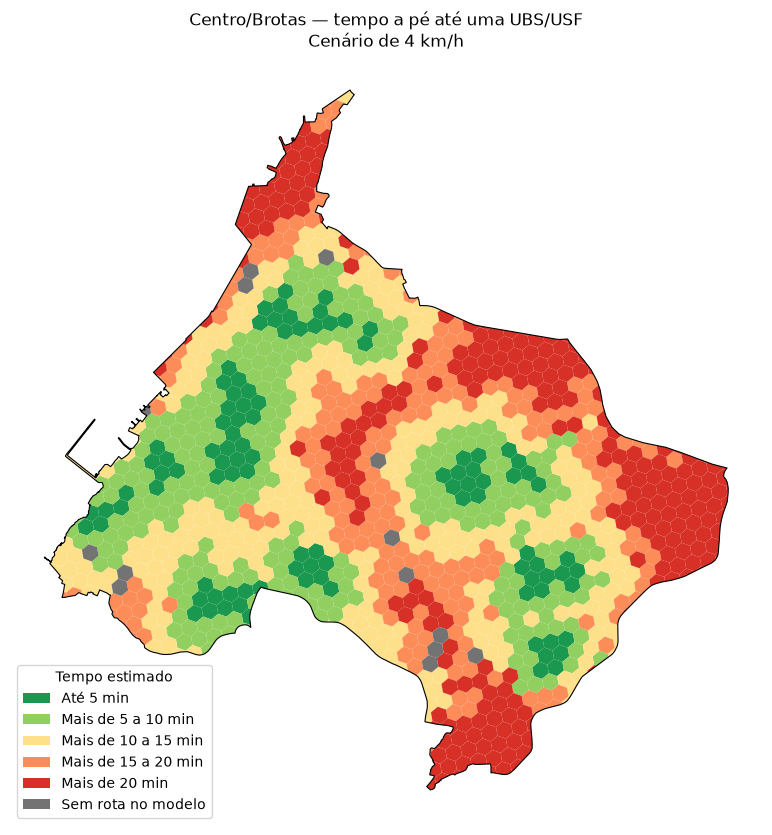

In [48]:
cores = ["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027", "#737373"]

fig, ax = plt.subplots(figsize=(10, 10))

for faixa, cor in zip(faixas, cores):
    trecho = grade_caminhada.loc[grade_caminhada["faixa_caminhada"] == faixa]
    trecho.plot(ax=ax, color=cor, linewidth=0)

piloto.boundary.plot(ax=ax, color="black", linewidth=0.8)

from matplotlib.patches import Patch

ax.legend(
    handles=[Patch(facecolor=cor, label=faixa) for faixa, cor in zip(faixas, cores)],
    title="Tempo estimado",
    loc="lower left"
)
ax.set_title("Centro/Brotas — tempo a pé até uma UBS/USF\nCenário de 4 km/h")
ax.set_axis_off()

plt.show()

In [49]:
from pathlib import Path

saida = Path("../resultados")
saida.mkdir(parents=True, exist_ok=True)

fig.savefig(
    saida / "centro_brotas_tempo_caminhada_4kmh.png",
    dpi=300,
    bbox_inches="tight"
)

In [50]:
amostra = cobertura.copy()

amostra["via_extremidade"] = [
    math.isclose(tempo, tempos_celulas[i], rel_tol=0, abs_tol=1e-6)
    for i, tempo in amostra["tempo_s"].items()
]

faixas_teste = ["Até 5 min", "Mais de 20 min"]

casos = (
    amostra.loc[
        com_rota
        & amostra["via_extremidade"]
        & amostra["faixa_caminhada"].isin(faixas_teste)
    ]
    .sort_values("pop_estimada", ascending=False)
    .drop_duplicates("faixa_caminhada")
    .copy()
)

casos["tempo_min"] = (casos["tempo_s"] / 60).round(2)

print(casos[["h3_id", "faixa_caminhada", "tempo_min", "pop_estimada"]])

               h3_id faixa_caminhada  tempo_min  pop_estimada
736  8a8116b1989ffff  Mais de 20 min      26.35    856.843257
892  8a8116b1d297fff       Até 5 min       3.55    692.390416


In [51]:
rotas_teste = {}

for indice, caso in casos.iterrows():
    entrada = entradas_celulas[indice]
    u, v, _ = entrada["id_aresta"]

    no_saida, parcial_s = min(
        [(u, entrada["parcial_u_s"]), (v, entrada["parcial_v_s"])],
        key=lambda par: par[1] + tempos_ate_unidade.get(par[0], math.inf),
    )

    caminho = nx.dijkstra_path(
        rede_destinos, no_saida, destino_virtual, weight="tempo_s"
    )

    # Entre dois nós pode haver arestas paralelas. Guarde a de menor custo.
    trechos = [
        (a, b, min(rede_destinos[a][b],
                   key=lambda k: rede_destinos[a][b][k]["tempo_s"]))
        for a, b in zip(caminho, caminho[1:])
    ]

    chegada = rede_destinos.edges[trechos[-1]]
    indice_unidade = chegada["unidade_indice"]

    tempo_reconstruido_s = entrada["ligacao_s"] + parcial_s + sum(
        rede_destinos.edges[trecho]["tempo_s"] for trecho in trechos
    )

    assert math.isclose(
        tempo_reconstruido_s, caso["tempo_s"], rel_tol=0, abs_tol=1e-6
    ), f"Tempo divergente na célula {caso['h3_id']}"

    rotas_teste[indice] = {
        "trechos_rede": trechos[:-1],
        "no_saida": no_saida,
        "no_chegada": caminho[-2],
        "indice_unidade": indice_unidade,
    }

    nome_unidade = unidades_arestas.loc[indice_unidade, "unidade"]
    print(
        f"{caso['h3_id']} | {nome_unidade} | "
        f"{tempo_reconstruido_s / 60:.2f} min"
    )

8a8116b1989ffff | USF VALE DO MATATU (OLGA DE ALAKETU) | 26.35 min
8a8116b1d297fff | USF VALE DO MATATU (OLGA DE ALAKETU) | 3.55 min


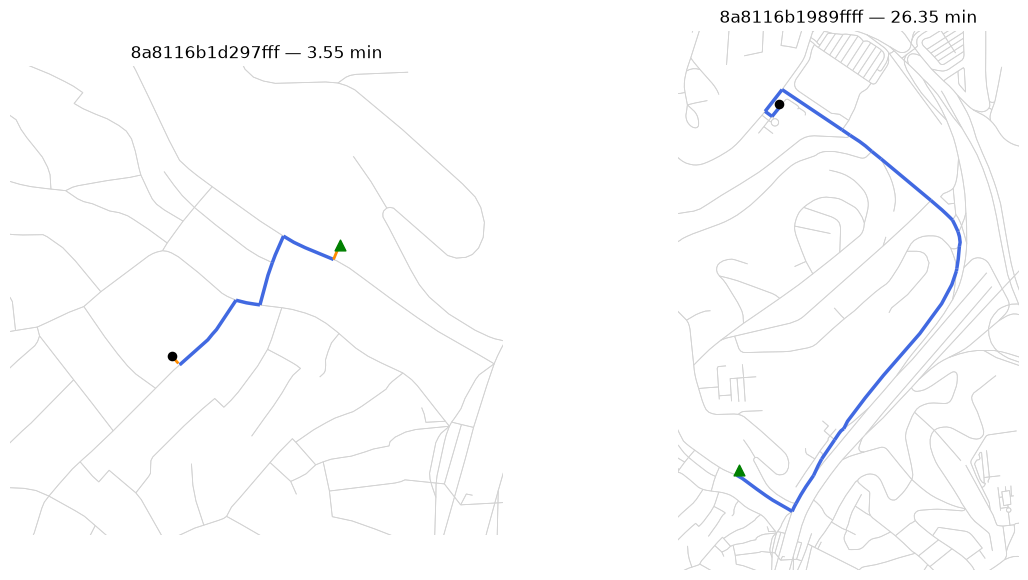

In [52]:
from shapely.geometry import LineString
from shapely.ops import substring

def trecho_parcial(entrada, no):
    u, v, chave = entrada["id_aresta"]
    linha = arestas.loc[(u, v, chave), "geometry"]
    posicao = linha.project(entrada["ponto_entrada"])
    extremo = 0 if no == u else linha.length
    return substring(linha, posicao, extremo)

fig, eixos = plt.subplots(1, 2, figsize=(14, 7))

for ax, (indice, caso) in zip(eixos, casos.sort_values("tempo_s").iterrows()):
    rota = rotas_teste[indice]
    origem = entradas_celulas[indice]
    destino = entradas_unidades[rota["indice_unidade"]]
    ponto_celula = celulas_arestas.loc[indice, "geometry"]
    ponto_usf = unidades_arestas.loc[rota["indice_unidade"], "geometry"]

    percurso = gpd.GeoSeries([
        trecho_parcial(origem, rota["no_saida"]),
        *[arestas.loc[trecho, "geometry"] for trecho in rota["trechos_rede"]],
        trecho_parcial(destino, rota["no_chegada"]),
    ], crs=arestas.crs)

    ligacoes = gpd.GeoSeries([
        LineString([ponto_celula, origem["ponto_entrada"]]),
        LineString([destino["ponto_entrada"], ponto_usf]),
    ], crs=arestas.crs)

    xmin, ymin, xmax, ymax = percurso.total_bounds
    margem = 150
    arestas.cx[xmin-margem:xmax+margem, ymin-margem:ymax+margem].plot(
        ax=ax, color="lightgray", linewidth=0.6
    )
    percurso.plot(ax=ax, color="royalblue", linewidth=2.5)
    ligacoes.plot(ax=ax, color="darkorange", linestyle="--", linewidth=2)
    ax.scatter(ponto_celula.x, ponto_celula.y, c="black", s=35, zorder=5)
    ax.scatter(ponto_usf.x, ponto_usf.y, c="green", s=60, marker="^", zorder=5)

    ax.set_xlim(xmin-margem, xmax+margem)
    ax.set_ylim(ymin-margem, ymax+margem)
    ax.set_title(f"{caso['h3_id']} — {caso['tempo_min']:.2f} min")
    ax.set_axis_off()

plt.show()

In [ ]:
#Utilizar como referencia para pesquisa no Google Maps
celulas_wgs84 = celulas_arestas.to_crs(epsg=4326)
unidades_wgs84 = unidades_arestas.to_crs(epsg=4326)

for indice, caso in casos.iterrows():
    indice_usf = rotas_teste[indice]["indice_unidade"]

    origem = celulas_wgs84.loc[indice, "geometry"]
    destino = unidades_wgs84.loc[indice_usf, "geometry"]

    print(f"Célula {caso['h3_id']} — {caso['tempo_min']:.2f} min")
    print(f"Partida: {origem.y:.7f}, {origem.x:.7f}")
    print(f"Chegada: {destino.y:.7f}, {destino.x:.7f}")
    print()

Célula 8a8116b1989ffff — 26.35 min
Partida: -12.9711181, -38.4822801
Chegada: -12.9795925, -38.4832063

Célula 8a8116b1d297fff — 3.55 min
Partida: -12.9804802, -38.4845743
Chegada: -12.9795925, -38.4832063



In [55]:
from urllib.parse import urlencode

indice = casos.index[casos["h3_id"] == "8a8116b1d297fff"][0]
indice_usf = rotas_teste[indice]["indice_unidade"]

origem = celulas_wgs84.loc[indice, "geometry"]
destino = unidades_wgs84.loc[indice_usf, "geometry"]

parametros = urlencode({
    "api": 1,
    "origin": f"{origem.y},{origem.x}",
    "destination": f"{destino.y},{destino.x}",
    "travelmode": "walking",
})

print("https://www.google.com/maps/dir/?" + parametros)

https://www.google.com/maps/dir/?api=1&origin=-12.980480219741308%2C-38.48457425354273&destination=-12.979592477033009%2C-38.48320625032113&travelmode=walking
